# SINDy in PyTorch: Discovering Governing Equations on the GPU

**Colin Casey, 2026.** A PyTorch implementation of *sparse identification of nonlinear dynamics* (SINDy) [1], the "discovering physics" theme of *Physics-AI Symbiosis* [2], continuing `discover.c` from this project.

| Section | Question |
|---|---|
| 1. The idea in plain English | What does SINDy actually do? |
| 2. The Lorenz system | Can it rediscover a chaotic system's three equations from data? |
| 3. Two ways to find the sparse coefficients | Thresholded least squares (STLSQ) vs. L1-penalized optimization in PyTorch (L-BFGS, and why plain Adam struggles) |
| 4. Does the discovered model behave like the real one? | Simulate both and compare |
| 5. How much noise can it take? | Recovery statistics over noise levels and random seeds |
| 6. Back to the falling apple, done properly | Discover $\dot v = -g$ (the dynamics), not $y(t)$ (one solution) |
| 7. What this shows | Conclusions |

Kernel: **py312** (PyTorch with CUDA).

In [1]:
import time, pathlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.prop_cycle': plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"])})
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DT = torch.float64
torch.manual_seed(0)
print('PyTorch', torch.__version__, '| device:', dev, torch.cuda.get_device_name(0) if dev.type == 'cuda' else '')

PyTorch 2.11.0+cu128 | device: cuda NVIDIA GeForce RTX 4060


---
## 1. The idea in plain English

Most laws of physics are **differential equations** with only a few terms. Newton's falling apple is $\dot v = -g$; the Lorenz weather model has seven terms in three equations. SINDy turns "find the law" into a regression with a twist:

1. Measure the state $\mathbf x(t)$ and estimate its rate of change $\dot{\mathbf x}(t)$.
2. Build a **library** $\Theta(\mathbf x)$ of candidate terms: $1, x, y, z, x^2, xy, \dots$
3. Solve $\dot{\mathbf x} \approx \Theta(\mathbf x)\,\Xi$ for the coefficient matrix $\Xi$, insisting that most entries be **exactly zero**.

The surviving terms *are* the discovered equations: readable, checkable, and able to predict, unlike a black-box network.

---
## 2. The Lorenz system

$$\dot x = \sigma(y - x),\qquad \dot y = x(\rho - z) - y,\qquad \dot z = xy - \beta z,\qquad \sigma = 10,\ \rho = 28,\ \beta = 8/3$$
Integrate it with fourth-order Runge-Kutta in PyTorch, then hide the equations and keep only the data.

In [2]:
SIG, RHO, BETA = 10.0, 28.0, 8.0/3.0
def lorenz(X):
    x, y, z = X[..., 0], X[..., 1], X[..., 2]
    return torch.stack([SIG*(y - x), x*(RHO - z) - y, x*y - BETA*z], dim=-1)

def rk4(f, x0, dt, n):
    X = torch.empty((n, x0.shape[-1]), dtype=DT, device=x0.device); X[0] = x0
    for k in range(n - 1):
        a = f(X[k]); b = f(X[k] + dt/2*a); c = f(X[k] + dt/2*b); d = f(X[k] + dt*c)
        X[k + 1] = X[k] + dt/6*(a + 2*b + 2*c + d)
    return X

dt, n = 0.002, 10_000
x0 = torch.tensor([-8.0, 7.0, 27.0], dtype=DT)
t0 = time.perf_counter()
X = rk4(lorenz, x0, dt, n)                       # on the CPU: 10,000 tiny sequential steps
print(f'simulated {n} RK4 steps in {time.perf_counter() - t0:.2f} s; x range [{X[:, 0].min():.1f}, {X[:, 0].max():.1f}]')

NAMES = ['1', 'x', 'y', 'z', 'x²', 'xy', 'xz', 'y²', 'yz', 'z²']
def library(X):
    x, y, z = X[:, 0], X[:, 1], X[:, 2]
    return torch.stack([torch.ones_like(x), x, y, z, x*x, x*y, x*z, y*y, y*z, z*z], dim=1)

XI_TRUE = torch.zeros(10, 3, dtype=DT)
XI_TRUE[1, 0], XI_TRUE[2, 0] = -SIG, SIG                                  # xdot = -10 x + 10 y
XI_TRUE[1, 1], XI_TRUE[2, 1], XI_TRUE[6, 1] = RHO, -1.0, -1.0             # ydot = 28 x - y - xz
XI_TRUE[3, 2], XI_TRUE[5, 2] = -BETA, 1.0                                 # zdot = -8/3 z + xy

def central_diff(X, dt):
    dX = torch.empty_like(X)
    dX[1:-1] = (X[2:] - X[:-2])/(2*dt); dX[0] = (X[1] - X[0])/dt; dX[-1] = (X[-1] - X[-2])/dt
    return dX

Xd = X.to(dev)
dX_fd = central_diff(Xd, dt)                      # derivatives estimated from the data alone
Theta = library(Xd)
print('library matrix on', Theta.device, 'shape', tuple(Theta.shape), '| derivative error from finite differences:',
      f'{(dX_fd - lorenz(Xd)).abs().max():.2e}')

simulated 10000 RK4 steps in 1.46 s; x range [-17.7, 16.6]
library matrix on cuda:0 shape (10000, 10) | derivative error from finite differences: 1.64e+00


---
## 3. Two ways to find the sparse coefficients

**(a) STLSQ** (the original SINDy algorithm): least squares, set every $|\xi| < \lambda$ to zero, re-solve on the survivors, repeat.

**(b) L1-penalized optimization**, the "PyTorch way": treat $\Xi$ as a trainable tensor and minimize
$$\mathcal L(\Xi) = \sum_j \frac{\|\dot X_j - \tilde\Theta\,\Xi_j\|^2}{\|\dot X_j\|^2} + \lambda_1\sum_{ij}\sqrt{\Xi_{ij}^2 + \epsilon}$$
(a smoothed L1 penalty) with autograd. Two practical details decide whether it works:
- **center and scale** the library columns ($\tilde\Theta$), so one $\lambda_1$ suits every term;
- use **L-BFGS** (quasi-Newton, built into `torch.optim`), and keep $\lambda_1$ small (here $10^{-5}$).

L1 shrinks but never gives *exact* zeros, so it is used to **select candidate terms**, followed by the same hard threshold and least-squares refit as STLSQ. For contrast, plain **Adam** on the same objective is run for 4,000 steps.

In [3]:
def stlsq(Theta, dX, lam=0.5, iters=10):
    Xi = torch.linalg.lstsq(Theta, dX).solution
    for _ in range(iters):
        small = Xi.abs() < lam
        Xi = Xi.masked_fill(small, 0.0)
        for j in range(dX.shape[1]):
            big = ~small[:, j]
            if big.any():
                Xi[big, j] = torch.linalg.lstsq(Theta[:, big], dX[:, j:j+1]).solution[:, 0]
    return Xi

def centered_library(Theta):
    mu = Theta.mean(0, keepdim=True); mu[:, 0] = 0.0          # leave the constant column alone
    sd = Theta.std(0, keepdim=True); sd[:, 0] = 1.0
    return (Theta - mu)/sd, mu, sd

def to_raw(Xs, mu, sd):
    W = Xs/sd.T
    W[0] = Xs[0] - (mu/sd) @ Xs                                # the constant absorbs the centering
    return W

def objective(Tc, dX, Xi, lam1):
    return ((Tc @ Xi - dX).pow(2).mean(0)/dX.pow(2).mean(0)).sum() + lam1*torch.sqrt(Xi**2 + 1e-8).sum()

def l1_lbfgs(Theta, dX, lam1=1e-5, rel=0.01, lam_hard=0.5):
    Tc, mu, sd = centered_library(Theta)
    Xi = torch.zeros(Theta.shape[1], dX.shape[1], dtype=DT, device=Theta.device, requires_grad=True)
    opt = torch.optim.LBFGS([Xi], lr=1, max_iter=500, history_size=50, line_search_fn='strong_wolfe',
                            tolerance_grad=1e-12, tolerance_change=1e-14)
    def closure():
        opt.zero_grad(); loss = objective(Tc, dX, Xi, lam1); loss.backward(); return loss
    for _ in range(5):
        opt.step(closure)
    Xs = Xi.detach()
    support = Xs.abs() >= rel*Xs.abs().max(dim=0, keepdim=True).values      # candidate terms chosen by L1
    W = torch.zeros_like(Xs)
    for j in range(dX.shape[1]):
        W[support[:, j], j] = torch.linalg.lstsq(Theta[:, support[:, j]], dX[:, j:j+1]).solution[:, 0]
    return stlsq_polish(Theta, dX, W, lam_hard), to_raw(Xs, mu, sd)

def stlsq_polish(Theta, dX, Xi, lam=0.5, iters=10):              # hard-threshold + refit, starting from Xi
    for _ in range(iters):
        small = Xi.abs() < lam
        Xi = Xi.masked_fill(small, 0.0)
        for j in range(dX.shape[1]):
            big = ~small[:, j]
            Xi[big, j] = torch.linalg.lstsq(Theta[:, big], dX[:, j:j+1]).solution[:, 0]
    return Xi

def adam_baseline(Theta, dX, lam1=1e-5, steps=4000, lr=1e-2):
    Tc, mu, sd = centered_library(Theta)
    Xi = torch.zeros(Theta.shape[1], dX.shape[1], dtype=DT, device=Theta.device, requires_grad=True)
    opt = torch.optim.Adam([Xi], lr=lr)
    for _ in range(steps):
        opt.zero_grad(); loss = objective(Tc, dX, Xi, lam1); loss.backward(); opt.step()
    return to_raw(Xi.detach(), mu, sd)

def show(Xi, title):
    print(title)
    for j, var in enumerate('xyz'):
        terms = ' '.join(f'{Xi[i, j].item():+.4f} {NAMES[i]}' for i in range(10) if Xi[i, j] != 0)
        print(f'  d{var}/dt = {terms}')

t0 = time.perf_counter(); Xi_st = stlsq(Theta, dX_fd); torch.cuda.synchronize() if dev.type == 'cuda' else None
t_st = time.perf_counter() - t0
t0 = time.perf_counter(); Xi_lb, Xi_lb_raw = l1_lbfgs(Theta, dX_fd); t_lb = time.perf_counter() - t0
t0 = time.perf_counter(); Xi_ad = adam_baseline(Theta, dX_fd); t_ad = time.perf_counter() - t0
show(Xi_st.cpu(), f'(a) STLSQ ({t_st*1e3:.0f} ms):')
show(Xi_lb.cpu(), f'(b) L1 + L-BFGS on {dev}, then threshold + refit ({t_lb:.1f} s):')
show(XI_TRUE, 'truth:')
print(f'\ncondition number of the centered library: {torch.linalg.cond(centered_library(Theta)[0]).item():.0f}')
print(f'raw L1 + L-BFGS solution before thresholding: {int((Xi_lb_raw.abs() > 1e-3).sum())} of 30 coefficients above 1e-3 '
      '(L1 shrinks, but leaves small non-zeros)')
print(f'plain Adam, same objective, 4000 steps ({t_ad:.1f} s): max coefficient error {(Xi_ad.cpu() - XI_TRUE).abs().max():.2f} '
      '-> first-order steps with a fixed learning rate have not converged\n')
for name, Xi in (('STLSQ', Xi_st), ('L1+L-BFGS', Xi_lb)):
    same = torch.equal(Xi.cpu() != 0, XI_TRUE != 0)
    print(f'{name:10s}: correct set of terms: {same};  max coefficient error {(Xi.cpu() - XI_TRUE).abs().max():.2e}')

(a) STLSQ (149 ms):
  dx/dt = -9.9990 x +9.9990 y
  dy/dt = +27.9925 x -0.9986 y -0.9998 xz
  dz/dt = -2.6663 z +0.9999 xy
(b) L1 + L-BFGS on cuda, then threshold + refit (3.4 s):
  dx/dt = -9.9990 x +9.9990 y
  dy/dt = +27.9925 x -0.9986 y -0.9998 xz
  dz/dt = -2.6663 z +0.9999 xy
truth:
  dx/dt = -10.0000 x +10.0000 y
  dy/dt = +28.0000 x -1.0000 y -1.0000 xz
  dz/dt = -2.6667 z +1.0000 xy

condition number of the centered library: 49
raw L1 + L-BFGS solution before thresholding: 13 of 30 coefficients above 1e-3 (L1 shrinks, but leaves small non-zeros)
plain Adam, same objective, 4000 steps (2.8 s): max coefficient error 30.32 -> first-order steps with a fixed learning rate have not converged

STLSQ     : correct set of terms: True;  max coefficient error 7.55e-03
L1+L-BFGS : correct set of terms: True;  max coefficient error 7.55e-03


---
## 4. Does the discovered model behave like the real one?

Integrate the discovered equations from the same starting point. Lorenz is **chaotic**: any difference, even $10^{-5}$ in a coefficient, grows like $e^{\lambda t}$ with Lyapunov exponent $\lambda \approx 0.9$, so trajectories must eventually separate. The right tests are short-term agreement and the same long-term "butterfly" shape.

discovered and true trajectories stay within 1 unit until t = 5.69 (about 5 Lyapunov times)


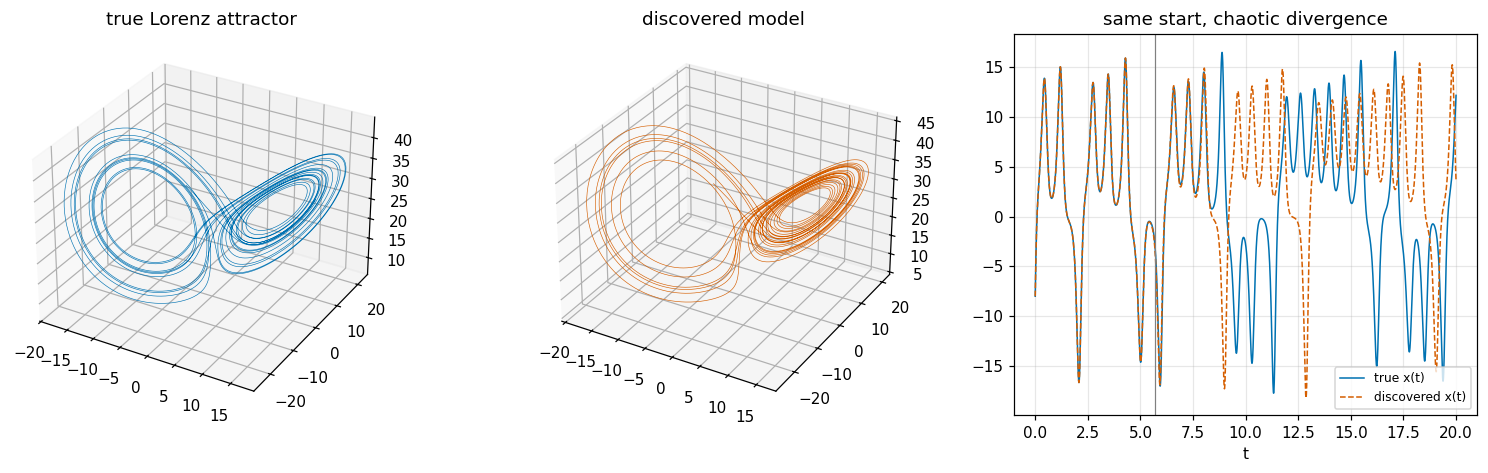

Figure: both 3-D plots show the same two-lobed butterfly. On the right the two x(t) curves lie on top of each other until the gray line, then drift apart, as chaos guarantees for any tiny difference.


In [4]:
Xi_found = Xi_st.cpu()
f_found = lambda S: (library(S.reshape(1, 3)) @ Xi_found).reshape(3)
Xs = rk4(f_found, x0, dt, n)
tt = np.arange(n)*dt
sep = (Xs - X).norm(dim=1).numpy()
t_sep = tt[np.argmax(sep > 1.0)] if (sep > 1.0).any() else np.inf
print(f'discovered and true trajectories stay within 1 unit until t = {t_sep:.2f} (about {t_sep*0.9:.0f} Lyapunov times)')

fig = plt.figure(figsize=(14, 4.4))
ax1 = fig.add_subplot(1, 3, 1, projection='3d')
ax1.plot(*X.numpy().T, lw=0.4, label='true'); ax1.set_title('true Lorenz attractor')
ax2 = fig.add_subplot(1, 3, 2, projection='3d')
ax2.plot(*Xs.numpy().T, lw=0.4, color='#D55E00'); ax2.set_title('discovered model')
ax3 = fig.add_subplot(1, 3, 3)
ax3.plot(tt, X[:, 0], '-', lw=1, label='true x(t)'); ax3.plot(tt, Xs[:, 0], '--', lw=1, label='discovered x(t)')
ax3.axvline(t_sep, color='gray', lw=0.8); ax3.set_xlabel('t'); ax3.set_title('same start, chaotic divergence'); ax3.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure: both 3-D plots show the same two-lobed butterfly. On the right the two x(t) curves lie on top of each '
      'other until the gray line, then drift apart, as chaos guarantees for any tiny difference.')

---
## 5. How much noise can it take?

Add Gaussian noise of standard deviation $\eta$ to the measured *states*, re-estimate the derivatives by finite differences, and ask: is the **exact** set of seven terms recovered? Ten random seeds per noise level. Finite differences amplify noise by about $1/\Delta t$, so this is a hard, honest test; smoothing the data first (as in section 6) helps.

 state noise η  raw finite differences  Savitzky-Golay smoothed
          0.00                     1.0                      1.0
          0.01                     1.0                      1.0
          0.10                     1.0                      1.0
          0.30                     0.1                      1.0
          1.00                     0.0                      0.5
          3.00                     0.0                      0.1


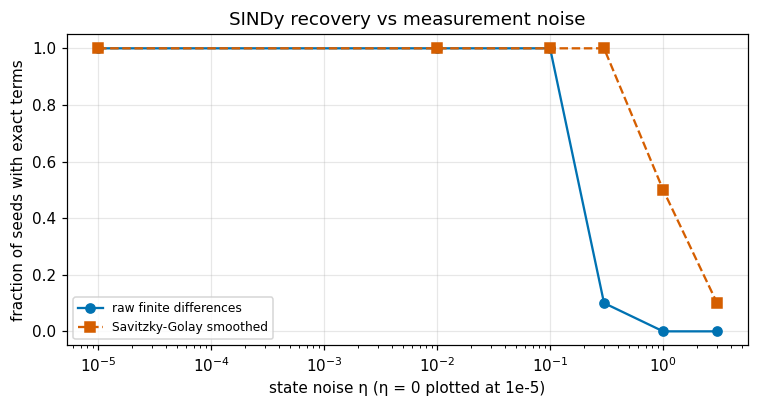

Figure: both curves start at 1 for small noise; the raw finite-difference curve drops first, and smoothing keeps exact recovery to a higher noise level before it too fails.


In [5]:
etas = [0.0, 1e-2, 1e-1, 0.3, 1.0, 3.0]
rows = []
for eta in etas:
    ok_st = ok_sm = 0
    for seed in range(10):
        g = torch.Generator(device=dev).manual_seed(seed)
        Xn = Xd + eta*torch.randn(Xd.shape, dtype=DT, device=dev, generator=g)
        ok_st += torch.equal((stlsq(library(Xn), central_diff(Xn, dt)).cpu() != 0), XI_TRUE != 0)
        Xsm = torch.tensor(savgol_filter(Xn.cpu().numpy(), 51, 3, axis=0), dtype=DT, device=dev)        # smoothed states
        dXsm = torch.tensor(savgol_filter(Xn.cpu().numpy(), 51, 3, deriv=1, delta=dt, axis=0), dtype=DT, device=dev)
        ok_sm += torch.equal((stlsq(library(Xsm), dXsm).cpu() != 0), XI_TRUE != 0)
    rows.append((eta, ok_st/10, ok_sm/10))
res = pd.DataFrame(rows, columns=['state noise η', 'raw finite differences', 'Savitzky-Golay smoothed'])
print(res.to_string(index=False))

plt.figure(figsize=(7, 3.8))
plt.semilogx([max(e, 1e-5) for e in etas], res.iloc[:, 1], 'o-', label='raw finite differences')
plt.semilogx([max(e, 1e-5) for e in etas], res.iloc[:, 2], 's--', label='Savitzky-Golay smoothed')
plt.xlabel('state noise η (η = 0 plotted at 1e-5)'); plt.ylabel('fraction of seeds with exact terms'); plt.ylim(-0.05, 1.05)
plt.legend(fontsize=8); plt.title('SINDy recovery vs measurement noise'); plt.tight_layout(); plt.show()
print('Figure: both curves start at 1 for small noise; the raw finite-difference curve drops first, and smoothing '
      'keeps exact recovery to a higher noise level before it too fails.')

---
## 6. Back to the falling apple, done properly

`discover.c` fitted the *solution* $y(t)$ against a library of functions of $t$, and needed a strong BIC penalty to avoid a spurious $\cos t$. SINDy instead looks for the *dynamics*: regress $\dot v$ on a library of the **state**, $\{1, y, v, y^2, yv, v^2\}$, and hope to find $\dot v = -g$ alone. That law holds for every throw, not just this one.

The catch: $\dot v$ is the second derivative of noisy positions. Plain finite differences turn 5 cm of noise into accelerations of tens of m/s². Savitzky-Golay filtering (a sliding local polynomial fit) estimates $v$ and $\dot v$ far more stably.

In [6]:
d = pd.read_csv(pathlib.Path('out') / 'discover_data.csv')
t_ = d.t.values; y_ = d.y_measured.values; h = t_[1] - t_[0]

def sindy_apple(y, v, a, label):
    Y, V, A = (torch.tensor(q, dtype=DT, device=dev) for q in (y, v, a))
    Th = torch.stack([torch.ones_like(Y), Y, V, Y*Y, Y*V, V*V], dim=1)
    Xi = stlsq(Th, A[:, None], lam=0.5)[:, 0].cpu()
    names = ['1', 'y', 'v', 'y²', 'yv', 'v²']
    eq = ' '.join(f'{Xi[i].item():+.3f} {names[i]}' for i in range(6) if Xi[i] != 0) or '0'
    print(f'{label:32s} dv/dt = {eq}')
    return Xi

v_fd = np.gradient(y_, h); a_fd = np.gradient(v_fd, h)
print(f'finite-difference accelerations: mean {a_fd.mean():.2f}, spread (std) {a_fd.std():.1f} m/s^2')
sindy_apple(y_, v_fd, a_fd, 'raw finite differences:')
win = 31
y_sg = savgol_filter(y_, win, 2); v_sg = savgol_filter(y_, win, 2, deriv=1, delta=h); a_sg = savgol_filter(y_, win, 2, deriv=2, delta=h)
Xi_apple = sindy_apple(y_sg, v_sg, a_sg, f'Savitzky-Golay (window {win}):')
print(f'\n-> discovered g = {-Xi_apple[0].item():.3f} m/s^2 (true 9.81; discover.c with BIC found 9.784)')

finite-difference accelerations: mean -10.56, spread (std) 21.8 m/s^2
raw finite differences:          dv/dt = -10.557 1
Savitzky-Golay (window 31):      dv/dt = -9.788 1

-> discovered g = 9.788 m/s^2 (true 9.81; discover.c with BIC found 9.784)


---
## 7. What this shows

- **SINDy rediscovers Lorenz exactly** from finite-difference derivatives: all seven terms, coefficients to $10^{-3}$ or better, and the discovered model reproduces the attractor.
- **Two optimizers, one answer, with care.** STLSQ (exact linear algebra, milliseconds) and the PyTorch route (smoothed L1 with L-BFGS to pick candidate terms, then threshold and refit) find the same equations. The PyTorch route is the one that plugs into neural networks and scales to huge libraries, but it only works with a centered library, a small penalty and a second-order optimizer: plain Adam with a fixed learning rate had not converged after 4,000 steps.
- **Chaos sets the test.** A perfect discovery still diverges from the truth after a few Lyapunov times; compare short-term trajectories and long-term statistics, not long-term paths.
- **Derivatives are the weak point.** Noise kills recovery first through the derivative estimate; smoothing buys roughly an order of magnitude of noise tolerance.
- **Dynamics beat curve fits.** For the apple, SINDy finds the law $\dot v = -g$ that holds for any throw, where fitting $y(t)$ only describes one trajectory and needed a strong simplicity prior.

This is the paper's symbiosis in miniature: the **library is the physics prior**, sparsity is Occam's razor, and PyTorch supplies the optimization machinery and the GPU.

## References

[1] S. L. Brunton, J. L. Proctor, and J. N. Kutz, "Discovering governing equations from data by sparse identification of nonlinear dynamical systems," *Proc. Natl. Acad. Sci.*, vol. 113, no. 15, pp. 3932–3937, 2016, doi: 10.1073/pnas.1517384113.

[2] B. Jalali, A. Kadambi, and V. Roychowdhury, "Physics-AI symbiosis," arXiv:2109.05959, 2021.

[3] E. N. Lorenz, "Deterministic nonperiodic flow," *J. Atmos. Sci.*, vol. 20, no. 2, pp. 130–141, 1963.

[4] D. P. Kingma and J. Ba, "Adam: A method for stochastic optimization," in *Proc. Int. Conf. Learn. Represent. (ICLR)*, 2015.

[5] A. Paszke *et al.*, "PyTorch: An imperative style, high-performance deep learning library," in *Adv. Neural Inf. Process. Syst. (NeurIPS)*, vol. 32, 2019.

[6] A. Savitzky and M. J. E. Golay, "Smoothing and differentiation of data by simplified least squares procedures," *Anal. Chem.*, vol. 36, no. 8, pp. 1627–1639, 1964.

*[1] matches the citation you provided (DOI added); the others are from memory: check before citing.*